In [119]:
#| code-fold: true
#| code-summary: "Importy"
import numpy as np
from matplotlib import pyplot

import PyMPDATA as mpd

In [120]:
#| include: false
print(f"PyMPDATA version: {mpd.__version__}")
print(mpd.__file__)

PyMPDATA version: 1.7.3
/home/jaksie/projects/s7/mup/.mup-venv/lib/python3.12/site-packages/PyMPDATA/__init__.py


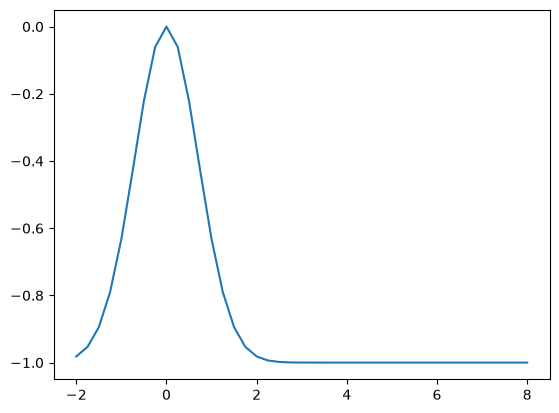

In [ ]:
pdf = lambda x: np.exp(-(x**2)) - 1  # PyMPDATA: założenie dodatniego sygnału

x = np.linspace(-2, 8, 41)
y = pdf(x)

pyplot.plot(x, y)
pyplot.show()

In [ ]:
#| code-fold: true
#| code-summary: "Importy `PyMPDATA`"
from PyMPDATA import (
    ScalarField,
    VectorField,
    Options,
    Stepper,
    Solver,
    boundary_conditions,
)


In [123]:
#| code-fold: true
#| code-summary: "Definicje"
#| output: false
common = {
    "halo": (options := Options(nonoscillatory=True)).n_halo,
    "boundary_conditions": (boundary_conditions.Periodic(),),
}
advector = VectorField(**common, data=(np.full(x.size + 1, 0.25),))
advectee = ScalarField(**common, data=y)

stepper = Stepper(n_dims=1, options=options)
solver = Solver(advectee=advectee, advector=advector, stepper=stepper)
solver.advance(n_steps=100)

41443.99

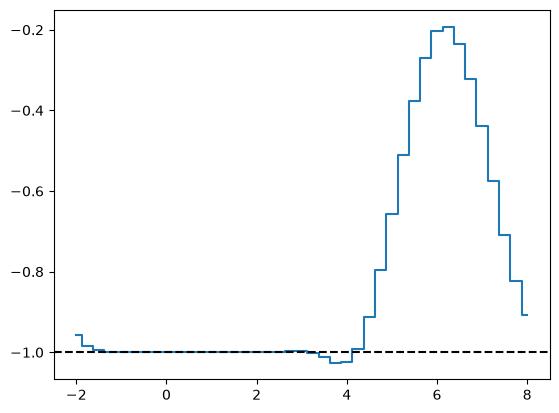

In [ ]:
#| code-fold: true
#| code-summary: "Przykład rozwiązania dla negatywnego sygnału"
pyplot.step(
    x,
    solver.advectee.get(),
    where="mid",
)

pyplot.axhline(
    -1,
    color="black",
    linestyle="--",
)
pyplot.show()